# get cell locations given data in a table

# plan

Load the transformed atlas labels.  This has a coordinate system in units of microns (~50 micron resolution).  And, we used the convention that 0 is in the center of the image.

Get the spatial coordinate of each pixel, and transform it to get the spatial coordinate of each tif file.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from os.path import join
import nibabel as nib

In [2]:
registration_output_dir = '/home/abenneck/mounts/bmaproot/nafs/shattuck/RodentToolsData/ZW-DT-1-P56-1/registration_outputs'
label_file = join(registration_output_dir,'transformed_atlas_labels.nii')
# NOTE
# fmost ontology is described here: fmost_ontology.csv in the registration output dir

In [3]:
vol = nib.load(label_file)
print(vol.affine)

[[ 5.00000000e+01  0.00000000e+00  0.00000000e+00 -3.59900000e+03]
 [ 0.00000000e+00  4.85159988e+01  0.00000000e+00 -8.01073779e+03]
 [ 0.00000000e+00  0.00000000e+00  4.85159988e+01 -6.82956006e+03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [4]:
L = np.array(vol.dataobj)

/tmp/ipykernel_1754465/3081927045.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  L = np.array(vol.dataobj)


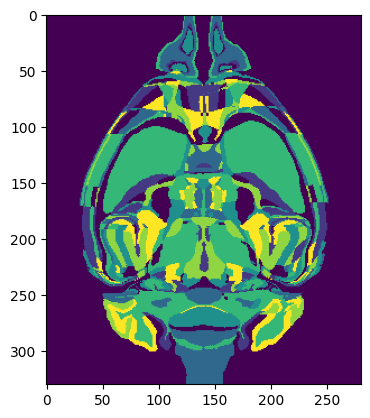

In [5]:
fig,ax = plt.subplots()
ax.imshow(L[0,L.shape[1]//2]%7)

In [6]:
o = vol.affine[:3,-1]
d = np.diag(vol.affine[:3,:3])
n = np.array(vol.shape[-3:])
xL = [np.arange(ni)*di + oi for ni,di,oi in zip(n,d,o)]


# tif files

We need to know the voxel spacing in the tif files.


In [7]:
dtif = np.array([2.0, 1.866, 1.866]) # todo, add more decimal places if we have them
otif = np.array([0,0,0])
ntif = np.array([3600,8587,7321]) # 3600 slices 8587 rows 7321 slices

# some example data

In [8]:
nexample = 20
c = np.random.randint(low=0,high=ntif-1,size=(nexample,3))
# c is expected to be what comes out of the pixel file

In [18]:
# convert it to microns using our convention for coordinate origin
c_microns = c*dtif - (ntif-1)/2*dtif 
# with the origin in the center, if the voxel index were (0,0,0) the location in microns woul dnot be (0,0,0)
# it would be -the size over 
c_microns

array([[-1207.   ,  -513.15 , -4644.474],
       [  687.   , -7798.014, -2968.806],
       [  439.   , -7547.97 ,  2892.3  ],
       [ 2229.   ,  1235.292,   205.26 ],
       [ 2781.   , -4584.762,  2476.182],
       [ 1313.   , -3493.152,   895.68 ],
       [-3383.   , -2319.438, -3955.92 ],
       [ 2091.   ,  2748.618, -6652.29 ],
       [  549.   ,  -598.986,  6320.142],
       [ -863.   ,  4245.15 , -6266.028],
       [-2721.   , -7605.816, -2099.25 ],
       [ 2053.   , -4120.128,   432.912],
       [  971.   , -3095.694,  3685.35 ],
       [ -463.   ,  -988.98 ,  3261.768],
       [  227.   ,  2513.502,  5749.146],
       [  857.   , -7704.714, -4084.674],
       [ -521.   ,  4898.25 ,  5004.612],
       [-2965.   ,  7924.902,  -811.71 ],
       [ 3085.   , -7876.386, -5769.672],
       [ 2155.   , -6857.55 , -5027.004]])

In [20]:
o

array([-3599.        , -8010.73779297, -6829.56005859])

In [17]:
# now figure out what voxel it corresponds to in our nifti label file
# if c_microns == 0 (the location of first voxel), then c_vox == 0
c_vox = (c_microns - o)/d
c_vox

array([[ 47.84      , 154.53846097,  45.03846382],
       [ 85.72      ,   4.38461122,  79.57692619],
       [ 80.76      ,   9.5384575 , 200.38462138],
       [116.56      , 190.57692336, 145.00000467],
       [127.6       ,  70.61538204, 191.8076981 ],
       [ 98.24      ,  93.11538257, 159.23077424],
       [  4.32      , 117.30769084,  59.23077185],
       [113.8       , 221.7692318 ,   3.65384745],
       [ 82.96      , 152.76923015, 271.03846922],
       [ 54.72      , 252.61538639,  11.6153861 ],
       [ 17.56      ,   8.34614978,  97.50000354],
       [113.04      ,  80.19230534, 149.69231248],
       [ 91.4       , 101.30769046, 216.73077562],
       [ 62.72      , 144.73076842, 208.00000618],
       [ 76.52      , 216.92307784, 259.26923817],
       [ 89.12      ,   6.30768819,  56.57692564],
       [ 61.56      , 266.07692517, 243.92308396],
       [ 12.68      , 328.46154205, 124.03846571],
       [133.68      ,   2.76922657,  21.84615558],
       [115.08      ,  23.76922

In [16]:
# now round this to the nearest voxel, and evaluate the label
c_vox_int = np.round(c_vox).astype(int)
c_vox_int

array([[ 48, 155,  45],
       [ 86,   4,  80],
       [ 81,  10, 200],
       [117, 191, 145],
       [128,  71, 192],
       [ 98,  93, 159],
       [  4, 117,  59],
       [114, 222,   4],
       [ 83, 153, 271],
       [ 55, 253,  12],
       [ 18,   8,  98],
       [113,  80, 150],
       [ 91, 101, 217],
       [ 63, 145, 208],
       [ 77, 217, 259],
       [ 89,   6,  57],
       [ 62, 266, 244],
       [ 13, 328, 124],
       [134,   3,  22],
       [115,  24,  37]])

In [13]:
# evaluate L at these locations

In [15]:
cell_anatomical_labels = L[(np.zeros(c.shape[0],dtype=int), c_vox_int[:,0], c_vox_int[:,1], c_vox_int[:,2])]
cell_anatomical_labels

array([804,   0,   0, 716,   0, 465,   0,   0,   0,   0,   0, 843, 740,
       690,   0,   0,   0,   0,   0,   0], dtype=uint16)

In [ ]:
# add this to your datafame